# Scikit-Learn Basics: Your First Steps in Machine Learning
Welcome to Machine Learning! This notebook is the gateway to understanding how ML works and how scikit-learn helps you do it.

## 1. Types of Machine Learning
<img src="./images/ml_types_overview.jpg" width="800">

In this notebook, we focus on **Supervised Learning** — the most commonly used type in industry.

## 2. The ML Workflow
<img src="./images/ml_workflow.jpg" width="800">

Every ML project follows this pipeline:
1. Collect Data
2. Split Data
3. Preprocess
4. Train Model
5. Evaluate
6. Deploy

## 3. Built-in Datasets
Sklearn comes with several built-in toy datasets. Let's load the famous Iris flower dataset.

In [ ]:
%pip install scikit-learn

In [2]:
import numpy as np
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
iris = load_iris()

# Create a Pandas DataFrame for easier viewing
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df['species'] = pd.Categorical.from_codes(iris.target, iris.target_names)

df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


Let's visualize the dataset using Seaborn to see if different species can be separated based on their features.

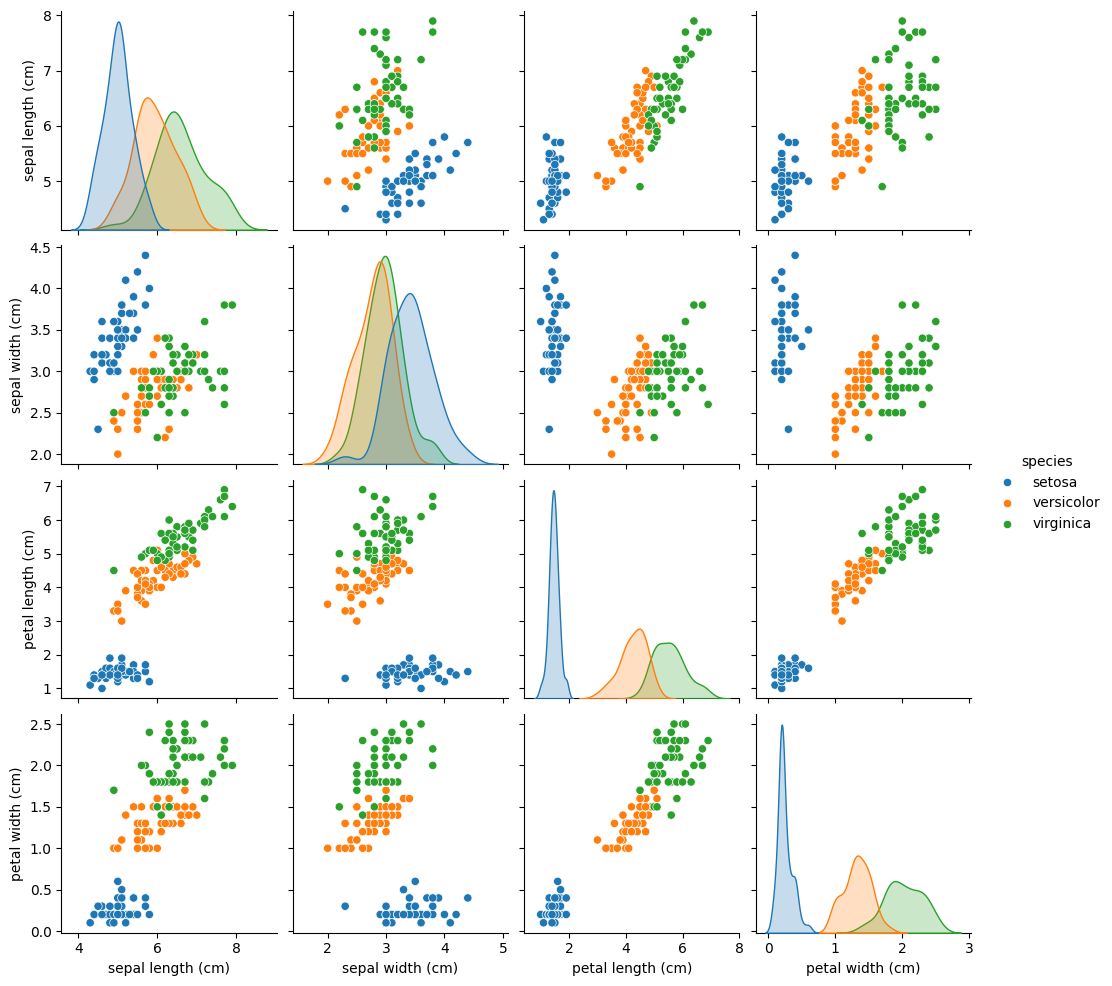

In [3]:
sns.pairplot(df, hue='species', height=2.5)
plt.show()

## 4. Train/Test Split
<img src="./images/train_test_split.jpg" width="800">

We must split our data into a training set and a test set to properly evaluate the model. We also use **stratification** to ensure class balance is preserved.

In [4]:
from sklearn.model_selection import train_test_split

X, y = iris.data, iris.target

# Split: 80% train, 20% test, with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,       # 20% for testing
    random_state=42,     # Reproducible split
    stratify=y           # Keep class ratios equal
)

print(f'Full dataset: X={X.shape}, y={y.shape}')
print(f'Training set: X={X_train.shape}, y={y_train.shape}')
print(f'Test set:     X={X_test.shape}, y={y_test.shape}')

Full dataset: X=(150, 4), y=(150,)
Training set: X=(120, 4), y=(120,)
Test set:     X=(30, 4), y=(30,)


## 5. Feature Scaling
Many ML algorithms compute distances between data points. We need to scale features so they all have a similar range.

**CRITICAL RULE:** Fit the scaler on the **training data only** to avoid data leakage.

In [5]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# FIT and TRANSFORM on training data
X_train_scaled = scaler.fit_transform(X_train)

# ONLY TRANSFORM on test data
X_test_scaled = scaler.transform(X_test)

print('Before scaling (first 2 samples):')
print(X_train[:2])
print('\nAfter scaling:')
print(X_train_scaled[:2].round(2))

Before scaling (first 2 samples):
[[4.4 2.9 1.4 0.2]
 [4.9 2.5 4.5 1.7]]

After scaling:
[[-1.72 -0.33 -1.35 -1.32]
 [-1.12 -1.23  0.41  0.65]]


## 6. Your First Model: K-Nearest Neighbors (KNN)
KNN makes predictions based on similarity. To classify a new flower, it finds the K closest training flowers and takes a vote.

<img src="./images/overfitting_underfitting.jpg" width="800">

In [6]:
from sklearn.neighbors import KNeighborsClassifier

# Create and train the model
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

# Make predictions
y_pred = knn.predict(X_test_scaled)

# Overall accuracy
accuracy = knn.score(X_test_scaled, y_test)
print(f'Test Accuracy: {accuracy:.2%}')

Test Accuracy: 93.33%


## 7. Evaluation Metrics
Getting a single accuracy number is not enough. You need to understand how the model is making mistakes using a Confusion Matrix.

<img src="./images/confusion_matrix_explained.jpg" width="800">

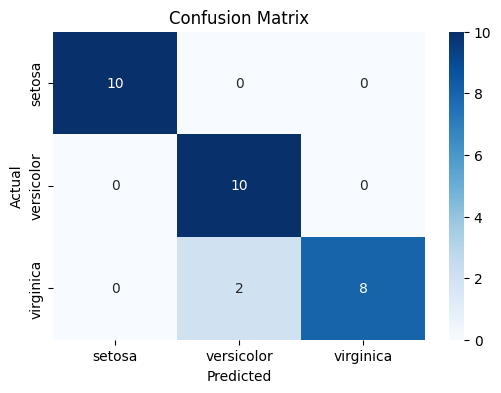

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



In [7]:
from sklearn.metrics import confusion_matrix, classification_report

# Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Full report with precision, recall, F1
print(classification_report(y_test, y_pred, target_names=iris.target_names))

## 8. Cross-Validation
A single train/test split might be lucky. Cross-validation gives a more reliable estimate by testing on multiple different splits.

CV Scores: [0.9667 0.9667 0.9333 0.9333 1.    ]
Mean CV Accuracy: 96.00% ± 2.49%


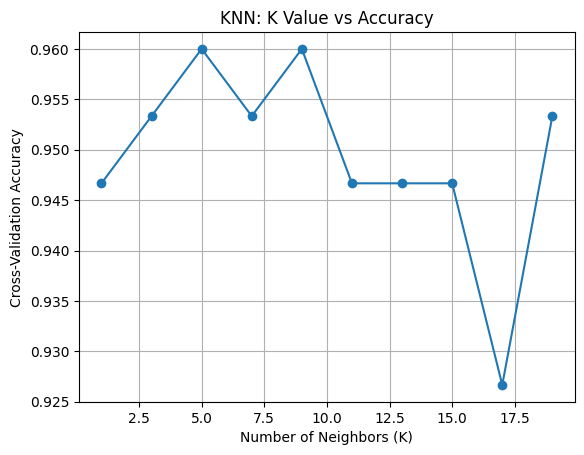

In [8]:
from sklearn.model_selection import cross_val_score

# Scale the full dataset for this example
# (In practice, use a Pipeline as shown in the next section!)
X_scaled = scaler.fit_transform(X)

# 5-fold cross-validation
cv_scores = cross_val_score(knn, X_scaled, y, cv=5, scoring='accuracy')

print(f'CV Scores: {cv_scores.round(4)}')
print(f'Mean CV Accuracy: {cv_scores.mean():.2%} ± {cv_scores.std():.2%}')

# Visualize K vs Accuracy
k_values = list(range(1, 21, 2))
mean_scores = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_scaled, y, cv=5)
    mean_scores.append(scores.mean())

plt.plot(k_values, mean_scores, marker='o')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Cross-Validation Accuracy')
plt.title('KNN: K Value vs Accuracy')
plt.grid(True)
plt.show()

## 9. Pipelines: Putting It All Together
Pipelines chain preprocessing steps and the model into a single object. This prevents data leakage and makes code reproducible.

In [9]:
from sklearn.pipeline import Pipeline

# Create a pipeline: scaler -> model
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

# Cross-validate the ENTIRE pipeline (leak-free!)
pipe_cv_scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
print(f'Pipeline CV Accuracy: {pipe_cv_scores.mean():.2%} ± {pipe_cv_scores.std():.2%}')

# Train the pipeline
pipe.fit(X_train, y_train)

# Predict new data (scaling is handled automatically!)
new_flowers = np.array([
    [5.1, 3.5, 1.4, 0.2],  # Looks like setosa
    [6.7, 3.0, 5.2, 2.3],  # Looks like virginica
])

predictions = pipe.predict(new_flowers)
for flower, pred in zip(new_flowers, predictions):
    print(f'{flower} -> {iris.target_names[pred]}')

Pipeline CV Accuracy: 96.67% ± 3.12%
[5.1 3.5 1.4 0.2] -> setosa
[6.7 3.  5.2 2.3] -> virginica
